# Reto 4 — Interpretación de segmentos

Objetivo: describir los 5 clusters del Reto 3 en **lenguaje de negocio**, con un perfil claro y un nombre descriptivo por segmento que un equipo de marketing pueda entender y utilizar.

Método:

1. Perfilar cada cluster en **unidades reales** (meses, años, €, %) — no con la matriz escalada del modelo.
2. Comparar cada cluster con la **media global**, en desviaciones típicas, para saber qué lo distingue de verdad.
3. Nombrar cada segmento a partir de sus **rasgos más distintivos**, con las cifras que lo justifican.
4. Proponer una acción de marketing y un canal por segmento, ligados a los objetivos del reto (ofertas de vehículos, planes de mantenimiento, fidelización y comunicación personalizada).

> Requisito: ejecutar antes `02_feature_engineering.ipynb` y `03_kmeans.ipynb`, que generan `data/processed/`.

## Resumen

**Qué se hizo:** perfil de cada cluster en unidades reales comparado con la media global, nombre de negocio para cada segmento y una acción de marketing por segmento.

| Segmento | % | Qué lo define | Acción |
|---|---|---|---|
| **Fieles Acomodados** | 28,6 | Mayor antigüedad y poder adquisitivo, leasing, Suiza | Fidelización y renovación anticipada |
| **Candidatos a Renovación** | 33,7 | Coche de combustión antiguo, sin financiación, más joven | Renovación con bono de entrega + financiación |
| **Pioneros Eléctricos** | 15,1 | 94 % enchufables, coche más nuevo | Servicios de carga y renovación a nuevos EQ |
| **Clientes Silenciosos** | 12,5 | Solo aceptan ePost | Recuperar el consentimiento |
| **Clientes Perdidos** | 10,1 | Sin vehículo actual | Campaña de recuperación (win-back) |

- Lo que separa a los clientes es su **relación con la marca** (antigüedad, vehículo actual, financiación, consentimiento) y la **motorización**, no la gama del coche ni la forma de conducir (secciones 2 y 5).
- Los nombres se asignan con **reglas sobre los rasgos** (sección 3), así que siguen siendo válidos aunque K-Means renumere los clusters. Las fichas completas están en la sección 6.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", None)

PROCESSED = next(p for p in (Path("data/processed"), Path("../data/processed")) if p.exists())
RAW = next(p for p in (Path("datos_reto_mercedes_benz_malackathon.csv"), Path("../datos_reto_mercedes_benz_malackathon.csv")) if p.exists())

clients = pd.read_csv(PROCESSED / "client_features.csv", index_col="client_id")
clusters = pd.read_csv(PROCESSED / "clusters.csv", index_col="client_id")["cluster"]
clients = clients.join(clusters, how="inner")

# Consents per channel (only their mean was used in the model)
CONSENTS = {
    "consent_phone_communication_channel": "teléfono",
    "consent_epost_communication_channel": "ePost",
    "consent_post_communication_channel": "correo postal",
}
consents = (pd.read_csv(RAW, index_col=0, usecols=["Unnamed: 0", "client_id", *CONSENTS])
            .groupby("client_id")[list(CONSENTS)].first().astype(bool).rename(columns=CONSENTS))
clients = clients.join(consents)

print(f"Clientes: {len(clients):,} | clusters: {clients['cluster'].nunique()}")
clients["cluster"].value_counts().sort_index().to_frame("clientes").assign(**{"%": lambda d: d["clientes"] / d["clientes"].sum() * 100})

Clientes: 173,454 | clusters: 5


,clientes,%
cluster,,
0,49610,28.60
1,17561,10.12
2,21646,12.48
3,26257,15.14
4,58380,33.66


## 1. Perfil numérico por cluster

Media de cada variable por cluster frente a la media global, en unidades reales. Se usan las variables del modelo y, además, variables **solo de perfilado** (edad, número total de vehículos) que no entraron en K-Means pero ayudan a describir a los clientes.

In [2]:
PROFILE = {
    "months_as_mb_customer": "Antigüedad como cliente (meses)",
    "n_current_vehicles": "Vehículos actuales",
    "n_vehicles_total": "Vehículos totales (actuales + pasados)",
    "has_past_vehicles": "% con vehículos pasados",
    "vehicle_age_years": "Edad del vehículo (años)",
    "workshop_visits_per_year": "Visitas de garantía/goodwill al año",
    "pct_plugin": "% vehículos enchufables",
    "has_telemetry": "% con vehículo conectado",
    "consent_level": "Nivel de consentimiento (0–1)",
    "purchasing_power_per_household_eur": "Poder adquisitivo por hogar (€)",
    "population": "Población del código postal",
    "age_ordinal": "Edad (ordinal 0 = <25 … 5 = 65+)",
}
PCT = ["has_past_vehicles", "pct_plugin", "has_telemetry"]

profile = clients.groupby("cluster")[list(PROFILE)].mean().T
profile["global"] = clients[list(PROFILE)].mean()
profile.loc[PCT] *= 100
profile.rename(index=PROFILE).style.format("{:,.1f}").background_gradient(axis=1, cmap="RdBu_r", subset=list(range(clients["cluster"].nunique())))

cluster,0,1,2,3,4,global
Antigüedad como cliente (meses),44.6,20.0,35.4,30.6,29.9,33.9
Vehículos actuales,1.2,0.0,1.1,1.1,1.1,1.0
Vehículos totales (actuales + pasados),2.2,1.7,1.8,1.5,1.4,1.7
% con vehículos pasados,32.0,100.0,25.4,24.1,12.5,30.3
Edad del vehículo (años),3.7,5.8,4.5,2.9,6.4,4.8
Visitas de garantía/goodwill al año,1.0,0.3,0.5,0.7,0.1,0.5
% vehículos enchufables,4.0,18.8,21.2,94.5,1.1,20.4
% con vehículo conectado,73.2,41.1,33.3,66.6,61.5,60.0
Nivel de consentimiento (0–1),1.0,0.9,0.4,1.0,1.0,0.9
Poder adquisitivo por hogar (€),"124,507.4","105,954.0","104,524.1","101,485.2","92,602.9","106,347.1"


## 2. ¿Qué distingue a cada cluster?

Para no nombrar los segmentos "a ojo", se calcula para cada variable la **diferencia estandarizada** entre la media del cluster y la media global:

$$d = \frac{\bar{x}_{cluster} - \bar{x}_{global}}{s_{global}}$$

Se expresa en desviaciones típicas, de modo que todas las variables son comparables (meses, €, %). Las categóricas se incluyen como el % de clientes en cada categoría. |d| > 0,5 es una diferencia relevante; |d| > 1, muy marcada.

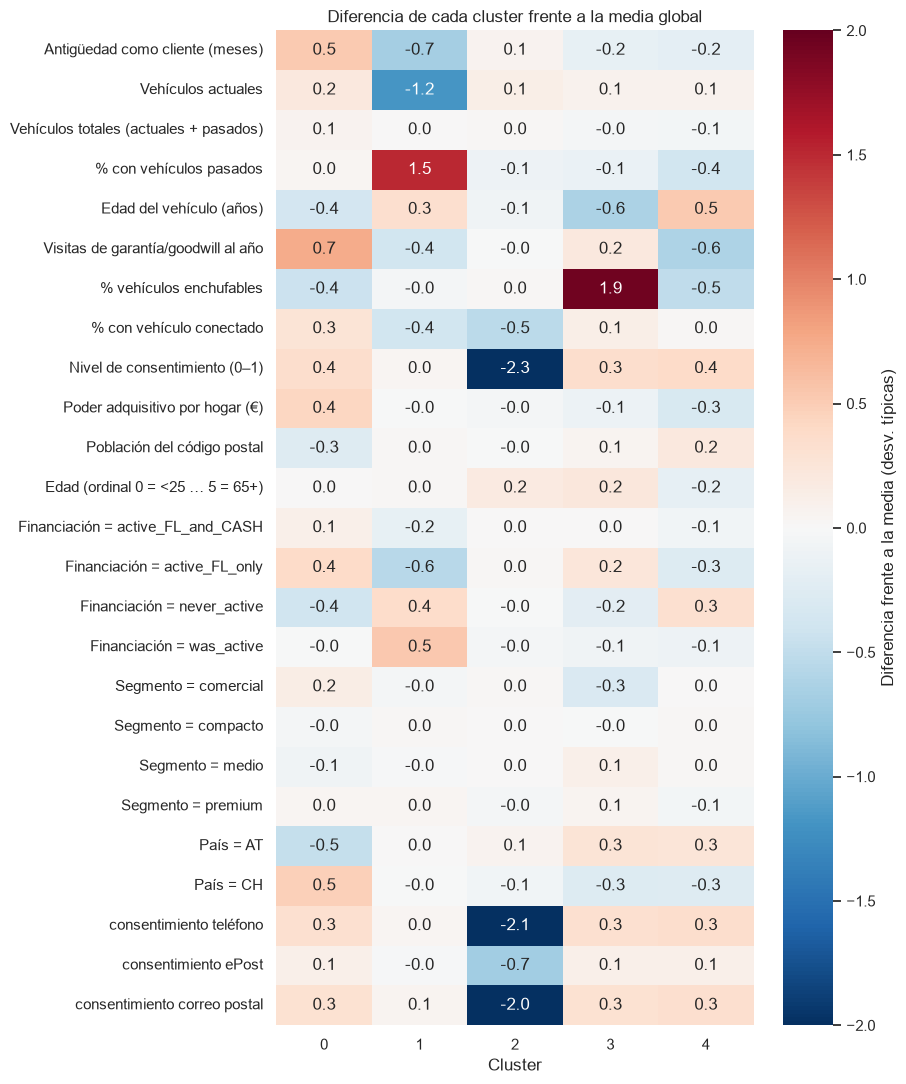

In [3]:
categorical = pd.get_dummies(
    clients[["finance_leasing_status", "main_segment", "country_code"]].rename(columns={
        "finance_leasing_status": "Financiación", "main_segment": "Segmento", "country_code": "País"}),
    prefix_sep=" = ").astype(float)
channels = clients[list(CONSENTS.values())].astype(float).add_prefix("consentimiento ")
features = pd.concat([clients[list(PROFILE)].rename(columns=PROFILE), categorical, channels], axis=1)

std_diff = ((features.groupby(clients["cluster"]).mean() - features.mean()) / features.std()).T

fig, ax = plt.subplots(figsize=(9, 11))
sns.heatmap(std_diff, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2, vmax=2,
            cbar_kws={"label": "Diferencia frente a la media (desv. típicas)"}, ax=ax)
ax.set(title="Diferencia de cada cluster frente a la media global", xlabel="Cluster", ylabel="")
plt.tight_layout()
plt.show()

In [4]:
def top_traits(column, n=4):
    top = column.abs().sort_values(ascending=False).head(n).index
    return ", ".join(f"{name} ({column[name]:+.1f})" for name in top)

std_diff.apply(top_traits).to_frame("Rasgos más distintivos (d)")

,Rasgos más distintivos (d)
cluster,
0,"Visitas de garantía/goodwill al año (+0.7), Antigüedad como cliente (meses) (+0.5), País = AT (-0.5), País = CH (+0.5)"
1,"% con vehículos pasados (+1.5), Vehículos actuales (-1.2), Antigüedad como cliente (meses) (-0.7), Financiación = active_FL_only (-0.6)"
2,"Nivel de consentimiento (0–1) (-2.3), consentimiento teléfono (-2.1), consentimiento correo postal (-2.0), consentimiento ePost (-0.7)"
3,"% vehículos enchufables (+1.9), Edad del vehículo (años) (-0.6), Nivel de consentimiento (0–1) (+0.3), consentimiento teléfono (+0.3)"
4,"Visitas de garantía/goodwill al año (-0.6), Edad del vehículo (años) (+0.5), % vehículos enchufables (-0.5), % con vehículos pasados (-0.4)"


**Interpretación**

- **Cluster 1**: lo define que **no tiene vehículos actuales** y sí vehículos pasados: son clientes que ya no conducen un Mercedes-Benz.
- **Cluster 2**: lo define un **consentimiento muy bajo**, sobre todo en teléfono y correo postal; también tiene menos vehículos conectados.
- **Cluster 3**: lo define la **electrificación**: casi todos sus vehículos son enchufables, y son los más nuevos.
- **Cluster 0**: más **visitas de taller en garantía**, la **mayor antigüedad** como cliente, predominio de **Suiza**, el **mayor poder adquisitivo** y más leasing.
- **Cluster 4**: pocas visitas de garantía, los **vehículos más antiguos**, casi nada enchufable, la zona con menor poder adquisitivo y sin historial de financiación.
- Las variables de telemetría (km por trayecto, velocidad) apenas cambian entre clusters, por lo que no aportan a la descripción (ver sección 5).

## 3. Nombre de cada segmento

Los nombres se asignan con **reglas sobre los rasgos distintivos** y no a mano sobre el número de cluster, para que sigan siendo correctos aunque K-Means numere los clusters de otra forma al reentrenar:

| Regla | Segmento |
|---|---|
| Menor nº de vehículos actuales | **Clientes Perdidos** |
| Menor nivel de consentimiento | **Clientes Silenciosos** |
| Mayor % de enchufables | **Pioneros Eléctricos** |
| De los dos restantes, mayor antigüedad como cliente | **Fieles Acomodados** |
| El restante | **Candidatos a Renovación** |

In [5]:
means = clients.groupby("cluster")[list(PROFILE)].mean()

names = {}
names[means["n_current_vehicles"].idxmin()] = "Clientes Perdidos"
names[means["consent_level"].drop(list(names)).idxmin()] = "Clientes Silenciosos"
names[means["pct_plugin"].drop(list(names)).idxmax()] = "Pioneros Eléctricos"
names[means["months_as_mb_customer"].drop(list(names)).idxmax()] = "Fieles Acomodados"
names[means.index.difference(list(names))[0]] = "Candidatos a Renovación"
assert len(names) == len(means), "Cada cluster debe tener un nombre único"

ORDER = ["Fieles Acomodados", "Candidatos a Renovación", "Pioneros Eléctricos", "Clientes Silenciosos", "Clientes Perdidos"]
clients["segmento"] = pd.Categorical(clients["cluster"].map(names), categories=ORDER, ordered=True)
PALETTE = dict(zip(ORDER, sns.color_palette("tab10", len(ORDER))))

sizes = clients["segmento"].value_counts().reindex(ORDER).to_frame("clientes")
sizes["%"] = sizes["clientes"] / sizes["clientes"].sum() * 100
sizes["cluster"] = [k for name in ORDER for k, v in names.items() if v == name]
sizes.style.format({"clientes": "{:,.0f}", "%": "{:.1f}"})

,clientes,%,cluster
segmento,,,
Fieles Acomodados,"49,610",28.6,0
Candidatos a Renovación,"58,380",33.7,4
Pioneros Eléctricos,"26,257",15.1,3
Clientes Silenciosos,"21,646",12.5,2
Clientes Perdidos,"17,561",10.1,1


## 4. Perfil categórico por segmento

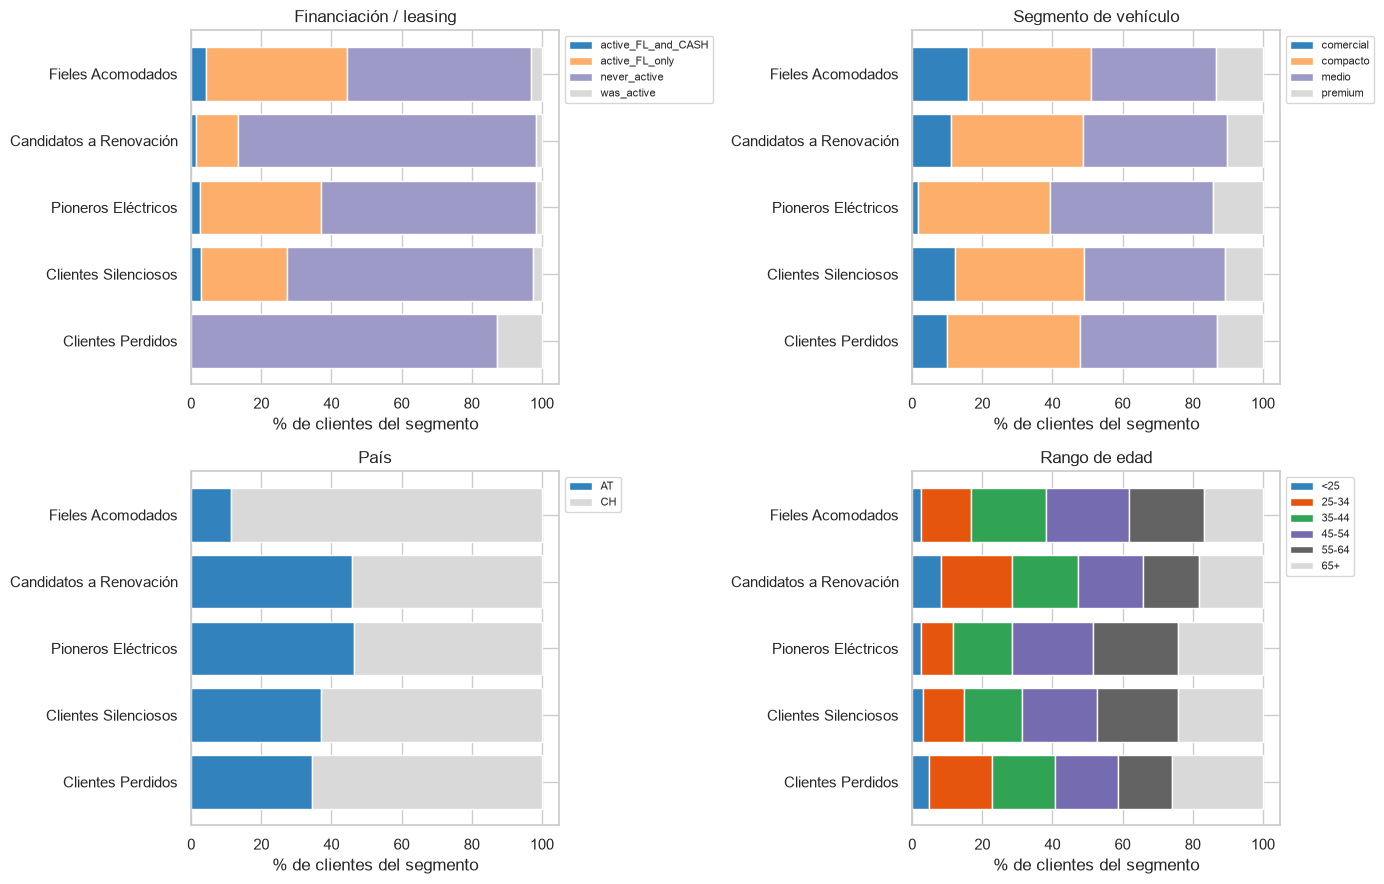

In [6]:
CATEGORICAL = {
    "finance_leasing_status": "Financiación / leasing",
    "main_segment": "Segmento de vehículo",
    "country_code": "País",
    "age_range": "Rango de edad",
}
AGE_ORDER = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (col, title) in zip(axes.flat, CATEGORICAL.items()):
    shares = pd.crosstab(clients["segmento"], clients[col], normalize="index") * 100
    if col == "age_range":
        shares = shares[AGE_ORDER]
    shares.plot(kind="barh", stacked=True, ax=ax, colormap="tab20c", width=0.8)
    ax.set(title=title, xlabel="% de clientes del segmento", ylabel="")
    ax.legend(bbox_to_anchor=(1, 1), fontsize=8)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

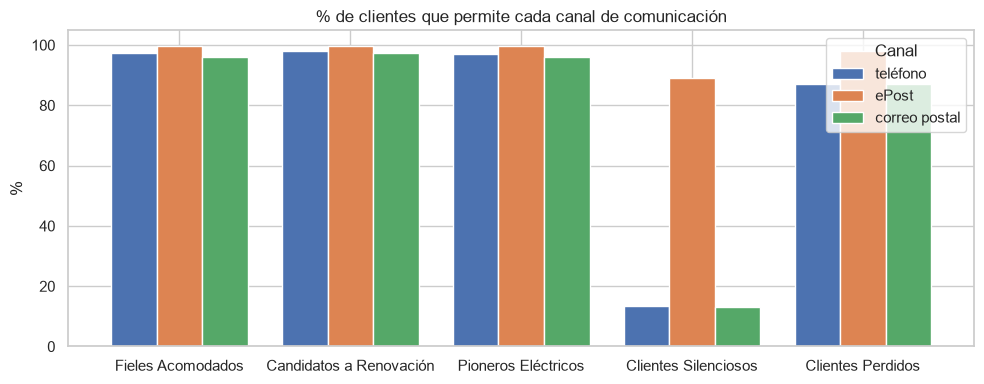

,teléfono,ePost,correo postal
segmento,,,
Fieles Acomodados,97.3,99.7,96.1
Candidatos a Renovación,98.1,99.8,97.3
Pioneros Eléctricos,97.0,99.7,96.0
Clientes Silenciosos,13.6,89.2,13.2
Clientes Perdidos,87.2,98.1,87.1


In [7]:
consent_share = clients.groupby("segmento", observed=True)[list(CONSENTS.values())].mean() * 100

ax = consent_share.plot(kind="bar", figsize=(10, 4), width=0.8)
ax.set(title="% de clientes que permite cada canal de comunicación", xlabel="", ylabel="%")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Canal")
plt.tight_layout()
plt.show()

consent_share.style.format("{:.1f}")

**Interpretación**

- **Financiación**: los Fieles Acomodados (40 % solo leasing) y los Pioneros Eléctricos (34 %) son los que más usan leasing; Candidatos a Renovación y Clientes Perdidos casi nunca han financiado (~85 % `never_active`). Los Clientes Perdidos son los únicos con un 13 % de financiación ya terminada (`was_active`).
- **Segmento de vehículo**: la mezcla compacto/medio/premium es parecida en todos; los Pioneros Eléctricos casi no tienen vehículos comerciales (2 %). El segmento de gama **no** es lo que separa a los clientes.
- **País**: los Fieles Acomodados son casi todos suizos (89 %); en el resto la proporción de Austria sube hasta el ~47 %.
- **Edad**: Candidatos a Renovación es el segmento más joven (47 % menor de 45 años); Pioneros Eléctricos y Clientes Silenciosos, los más mayores (~24 % de 65+).
- **Canales**: los Clientes Silenciosos solo pueden recibir **ePost** (89 %): teléfono y correo postal no llegan al 14 %. En el resto, los tres canales superan el 85 %.

## 5. Distribución de las variables clave

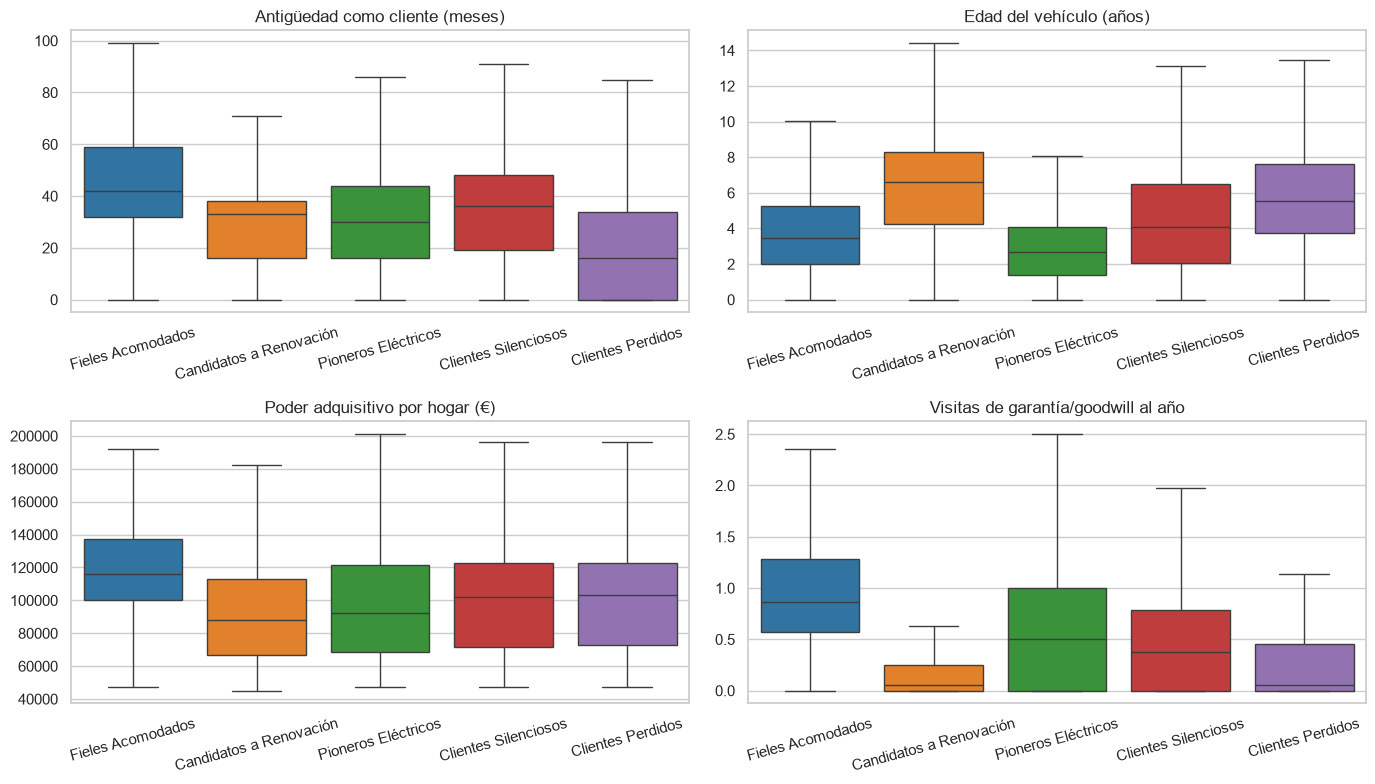

In [8]:
KEY = {
    "months_as_mb_customer": "Antigüedad como cliente (meses)",
    "vehicle_age_years": "Edad del vehículo (años)",
    "purchasing_power_per_household_eur": "Poder adquisitivo por hogar (€)",
    "workshop_visits_per_year": "Visitas de garantía/goodwill al año",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (col, title) in zip(axes.flat, KEY.items()):
    sns.boxplot(data=clients, x="segmento", y=col, hue="segmento", palette=PALETTE, showfliers=False, dodge=False, ax=ax, legend=False)
    ax.set(title=title, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [9]:
TELEMETRY = {
    "trip_distance_average": "Km medios por trayecto",
    "speed_average": "Velocidad media (km/h)",
    "operating_hours_total": "Horas de funcionamiento",
}
clients.groupby("segmento", observed=True)[list(TELEMETRY)].median().rename(columns=TELEMETRY)

,Km medios por trayecto,Velocidad media (km/h),Horas de funcionamiento
segmento,,,
Fieles Acomodados,14.23,49.02,603.84
Candidatos a Renovación,14.16,49.28,499.13
Pioneros Eléctricos,13.67,49.97,173.83
Clientes Silenciosos,14.42,50.25,448.82
Clientes Perdidos,14.35,49.31,401.72


**Interpretación**

- Los boxplots confirman que las diferencias no se deben a unos pocos valores extremos: la mediana de cada segmento se desplaza en la dirección que indica la sección 2 (p. ej., Fieles Acomodados con más antigüedad y poder adquisitivo; Candidatos a Renovación con los vehículos más antiguos).
- Los **Pioneros Eléctricos** tienen muchas menos horas de funcionamiento, coherente con vehículos más nuevos.
- Los km por trayecto y la velocidad media son casi iguales en todos los segmentos: **la forma de conducir no diferencia a los clientes**, por eso no se usa en los perfiles.

## 6. Fichas de segmento

Cifras en medias del segmento (entre paréntesis, la media global).

### Fieles Acomodados — 28,6 % (49.610 clientes)
**Perfil:** el cliente más consolidado de la marca. Lleva más tiempo con Mercedes-Benz, vive en zonas de alto poder adquisitivo de Suiza y renueva su vehículo con frecuencia mediante leasing.
- Antigüedad: **44,6 meses** (33,9) · poder adquisitivo: **124.500 €/hogar** (106.300) · 89 % en Suiza.
- 44 % con leasing activo · vehículo de **3,7 años** (4,8) · **1,0 visitas/año** de garantía (0,5).
- 73 % con vehículo conectado; solo un 4 % de vehículos enchufables.

**Acción:** **fidelización y renovación anticipada**. Ofrecer el siguiente leasing antes de que venza el actual, con prueba de un modelo electrificado (casi no tienen) y planes de mantenimiento premium incluidos. Programa de ventajas por antigüedad.
**Canal:** cualquiera (los tres canales > 96 %); atención personal desde el concesionario.

### Candidatos a Renovación — 33,7 % (58.380 clientes)
**Perfil:** el segmento más grande y más joven. Conduce un vehículo de combustión antiguo que compró al contado y vive en zonas más urbanas y de menor poder adquisitivo.
- Vehículo de **6,4 años** (4,8); el 69 % tiene más de 5 años · **1 %** enchufables (20 %).
- 85 % nunca ha financiado · poder adquisitivo **92.600 €/hogar** (106.300) · población del código postal **27.700** (20.100).
- 47 % menor de 45 años · solo **0,15 visitas/año** de garantía: la mayoría ya está fuera de garantía.

**Acción:** **campaña de renovación**: bono por entrega del vehículo usado + primera oferta de financiación o leasing con cuota de entrada baja, hacia modelos compactos electrificados. Mientras no renueve, **plan de mantenimiento post-garantía** para retenerlo en el taller oficial.
**Canal:** los tres canales (> 97 %); peso en digital por ser el segmento más joven.

### Pioneros Eléctricos — 15,1 % (26.257 clientes)
**Perfil:** cliente que ya ha dado el salto al vehículo enchufable, con el coche más nuevo de todos y a menudo en leasing.
- **94 %** de vehículos enchufables (20 %) · vehículo de **2,9 años** (4,8) · 37 % con leasing activo.
- 67 % con vehículo conectado · 24 % de 65 años o más · 47 % en Austria.

**Acción:** **servicios para el eléctrico**: wallbox, suscripción de carga y servicios conectados, mantenimiento específico de EV. Renovación hacia los nuevos modelos EQ al terminar el leasing y programa de recomendación (son los mejores embajadores de la electrificación).
**Canal:** app y canales digitales (vehículo conectado); los tres canales > 96 %.

### Clientes Silenciosos — 12,5 % (21.646 clientes)
**Perfil:** cliente con vehículo activo pero al que **casi no se puede contactar**: solo acepta comunicaciones por ePost.
- Nivel de consentimiento **0,39** (0,90): teléfono **14 %** y correo postal **13 %**, frente al 89 % de ePost.
- Por lo demás, cercano a la media: vehículo de 4,5 años, 35 meses de antigüedad · 24 % de 65 años o más.

**Acción:** **recuperar el consentimiento** antes de cualquier campaña: ofrecer algo de valor a cambio (recordatorios de mantenimiento, ofertas exclusivas) y pedir el permiso en cada visita al taller o al concesionario. Sin consentimiento, cualquier otra acción no llega.
**Canal:** **solo ePost** y contacto presencial en taller/concesionario.

### Clientes Perdidos — 10,1 % (17.561 clientes)
**Perfil:** antiguos clientes que **ya no tienen ningún Mercedes-Benz**: todos sus vehículos son pasados.
- **0 vehículos actuales** (1,0) · 100 % con vehículos pasados · antigüedad **20,0 meses** (33,9).
- 13 % con financiación ya terminada (`was_active`) · 26 % de 65 años o más.
- Siguen siendo contactables: teléfono y correo postal 87 %, ePost 98 %.

**Acción:** **campaña de recuperación (win-back)**: encuesta sobre el motivo de salida, oferta de vuelta (vehículo de ocasión certificado, condiciones de financiación como las que ya tuvieron) e invitación a probar los modelos nuevos.
**Canal:** teléfono y correo postal para un mensaje personal; ePost como recordatorio.

## 7. Resumen de segmentos

In [10]:
summary = pd.DataFrame({
    "Segmento": ORDER,
    "Rasgos clave": [
        "Mayor antigüedad y poder adquisitivo, leasing, Suiza",
        "Vehículo de combustión antiguo, sin financiación, más joven y urbano",
        "94 % enchufables, vehículo más nuevo, leasing",
        "Vehículo activo pero solo acepta ePost",
        "Sin vehículo actual: ya no es cliente activo",
    ],
    "Acción de marketing": [
        "Fidelización y renovación anticipada del leasing; prueba de modelos electrificados",
        "Renovación con bono de entrega + financiación; plan de mantenimiento post-garantía",
        "Servicios de carga y conectados; renovación a nuevos EQ; programa de recomendación",
        "Recuperar el consentimiento en taller y concesionario",
        "Win-back: encuesta de salida y oferta de vuelta",
    ],
    "Canal": ["Todos; concesionario", "Todos; digital", "App / digital", "Solo ePost; presencial", "Teléfono y correo postal"],
}).set_index("Segmento")
summary.insert(0, "% clientes", sizes["%"].round(1))
summary

,% clientes,Rasgos clave,Acción de marketing,Canal
Segmento,,,,
Fieles Acomodados,28.60,"Mayor antigüedad y poder adquisitivo, leasing, Suiza",Fidelización y renovación anticipada del leasing; prueba de modelos electrificados,Todos; concesionario
Candidatos a Renovación,33.70,"Vehículo de combustión antiguo, sin financiación, más joven y urbano",Renovación con bono de entrega + financiación; plan de mantenimiento post-garantía,Todos; digital
Pioneros Eléctricos,15.10,"94 % enchufables, vehículo más nuevo, leasing",Servicios de carga y conectados; renovación a nuevos EQ; programa de recomendación,App / digital
Clientes Silenciosos,12.50,Vehículo activo pero solo acepta ePost,Recuperar el consentimiento en taller y concesionario,Solo ePost; presencial
Clientes Perdidos,10.10,Sin vehículo actual: ya no es cliente activo,Win-back: encuesta de salida y oferta de vuelta,Teléfono y correo postal


## Conclusión

- Los 5 clusters de K-Means se traducen en **5 segmentos con sentido de negocio**, cada uno definido por pocos rasgos muy marcados y con una acción de marketing distinta:
  - **Fieles Acomodados** (28,6 %): fidelizar y renovar anticipadamente.
  - **Candidatos a Renovación** (33,7 %): la mayor oportunidad de venta y de electrificación.
  - **Pioneros Eléctricos** (15,1 %): servicios para el eléctrico y renovación a nuevos EQ.
  - **Clientes Silenciosos** (12,5 %): primero recuperar el consentimiento.
  - **Clientes Perdidos** (10,1 %): campaña de recuperación.
- Lo que separa a los clientes es su **relación con la marca** (antigüedad, vehículo actual o no, financiación, consentimiento) y la **motorización**, no el segmento de gama ni la forma de conducir.
- Dos segmentos (Clientes Silenciosos y Clientes Perdidos, 22,6 % en total) requieren un paso previo — recuperar el contacto o el vínculo — antes de cualquier campaña comercial.